In [ ]:
"""
Payment Behaviour & Digital Payment Intelligence
Fundamentals of Machine Learning (MLE2503)

IMPORTANT:
- The included CSV is a synthetic teaching dataset generated for this project.
- Replace it with faculty-provided/approved real data if available.
- This project performs unsupervised customer segmentation; it does not predict fraud.
"""
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
PLOT_DIR = ROOT / "plots"
PLOT_DIR.mkdir(exist_ok=True)


**Colab note:** Charts are displayed inline as well as saved to the `plots` folder. If no chart appears, rerun the relevant cell after uploading `synthetic_payment_transactions.csv` to `/content`.


## 2. Load and inspect the data

In [ ]:
# 1. Load and inspect transaction-level data
df = pd.read_csv(ROOT / "synthetic_payment_transactions.csv")
print("First five rows:\n", df.head())
print("\nLast five rows:\n", df.tail())
print("\nShape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nDescriptive statistics:\n", df.describe(include="all").T)
print("\nMissing values:\n", df.isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())


First five rows:
    transaction_id  customer_id transaction_date payment_mode  \
0               1        10001       2025-01-23          UPI   
1               2        10001       2025-12-26          UPI   
2               3        10001       2025-11-05         Cash   
3               4        10001       2025-05-27          UPI   
4               5        10001       2025-05-05          UPI   

   transaction_amount  cashback_used  discount_percent  emi_used  \
0              867.24              1              5.41         0   
1              669.20              1             14.04         0   
2              376.44              1              4.36         0   
3              797.59              1             10.16         0   
4             1227.71              1              9.52         0   

          channel  
0  Physical Store  
1         Website  
2             App  
3         Website  
4             App  

Last five rows:
        transaction_id  customer_id transaction_dat

## 3. Clean records

In [ ]:
# 2. Clean records. A duplicate transaction_id indicates a duplicated transaction.
df = df.drop_duplicates(subset="transaction_id", keep="first").copy()
df["transaction_date"] = pd.to_datetime(df["transaction_date"], errors="coerce")
df["payment_mode"] = df["payment_mode"].fillna("Unknown")
df["channel"] = df["channel"].fillna("Unknown")
df["transaction_amount"] = pd.to_numeric(df["transaction_amount"], errors="coerce")
df = df.dropna(subset=["customer_id", "transaction_amount", "transaction_date"])
df = df[df["transaction_amount"] > 0]

# Cap extreme transaction values at the 99th percentile. This limits the effect of
# extreme values on distance-based clustering while retaining most observations.
upper = df["transaction_amount"].quantile(.99)
df["transaction_amount"] = df["transaction_amount"].clip(upper=upper)
df["discount_percent"] = df["discount_percent"].clip(0, 100)


## 4. Exploratory data analysis

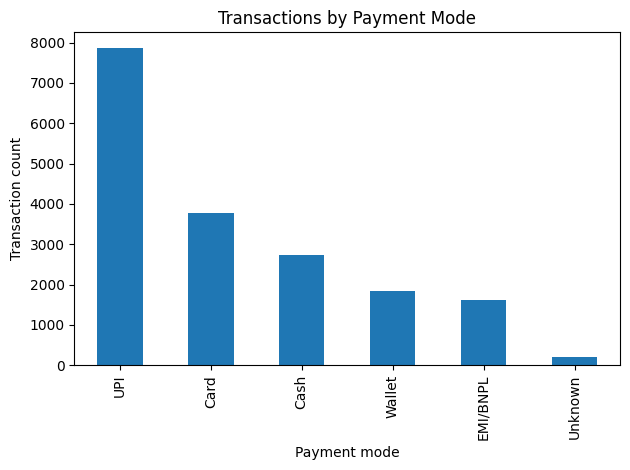

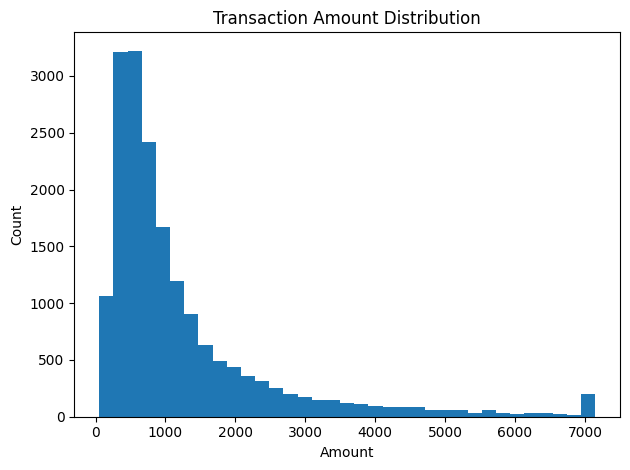

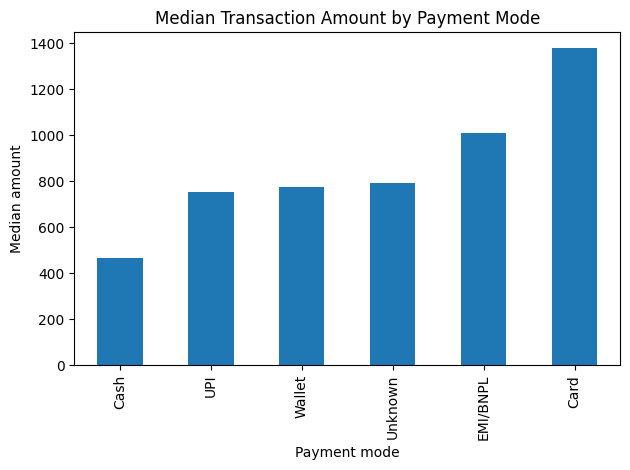

In [ ]:
# 3. EDA plots
plt.figure()
df["payment_mode"].value_counts().plot(kind="bar")
plt.title("Transactions by Payment Mode"); plt.xlabel("Payment mode"); plt.ylabel("Transaction count")
plt.tight_layout(); plt.savefig(PLOT_DIR/"payment_mode_counts.png", dpi=160); plt.show(); plt.close()

plt.figure()
df["transaction_amount"].plot(kind="hist", bins=35)
plt.title("Transaction Amount Distribution"); plt.xlabel("Amount"); plt.ylabel("Count")
plt.tight_layout(); plt.savefig(PLOT_DIR/"transaction_amount_distribution.png", dpi=160); plt.show(); plt.close()

plt.figure()
df.groupby("payment_mode")["transaction_amount"].median().sort_values().plot(kind="bar")
plt.title("Median Transaction Amount by Payment Mode"); plt.xlabel("Payment mode"); plt.ylabel("Median amount")
plt.tight_layout(); plt.savefig(PLOT_DIR/"median_amount_by_mode.png", dpi=160); plt.show(); plt.close()


## 5. Customer-level feature engineering

In [ ]:
# 4. Aggregate transactions to customer-level features
df["is_digital"] = df["payment_mode"].isin(["UPI", "Wallet"]).astype(int)
df["is_card"] = (df["payment_mode"] == "Card").astype(int)
df["is_cash"] = (df["payment_mode"] == "Cash").astype(int)
df["is_emi_mode"] = (df["payment_mode"] == "EMI/BNPL").astype(int)
df["is_unknown_mode"] = (df["payment_mode"] == "Unknown").astype(int)
df["month"] = df["transaction_date"].dt.month

customer = df.groupby("customer_id").agg(
    transaction_count=("transaction_id", "nunique"),
    total_spend=("transaction_amount", "sum"),
    average_transaction_value=("transaction_amount", "mean"),
    median_transaction_value=("transaction_amount", "median"),
    cashback_usage_rate=("cashback_used", "mean"),
    average_discount_percent=("discount_percent", "mean"),
    emi_usage_rate=("emi_used", "mean"),
    digital_payment_ratio=("is_digital", "mean"),
    card_payment_ratio=("is_card", "mean"),
    cash_payment_ratio=("is_cash", "mean"),
    emi_payment_ratio=("is_emi_mode", "mean"),
    unknown_payment_ratio=("is_unknown_mode", "mean"),
    channel_diversity=("channel", "nunique"),
    active_months=("month", "nunique")
).reset_index()

# Ratios should sum to approximately 1 across the four mutually exclusive modes
# when all mode values are known; Unknown is handled separately in raw data.
customer.to_csv(ROOT/"customer_level_features.csv", index=False)
print("\nCustomer-level feature sample:\n", customer.head())
print("\nCustomer feature dimensions:", customer.shape)



Customer-level feature sample:
    customer_id  transaction_count  total_spend  average_transaction_value  \
0        10001                 27   28926.7400                1071.360741   
1        10002                 14   40562.6376                2897.331257   
2        10003                 27   25978.6200                 962.171111   
3        10004                 19   17090.2000                 899.484211   
4        10005                 33   18830.5000                 570.621212   

   median_transaction_value  cashback_usage_rate  average_discount_percent  \
0                   847.720             0.888889                  7.945556   
1                  2314.745             0.071429                  1.100000   
2                   764.630             0.851852                  6.565556   
3                   843.650             0.947368                  5.843684   
4                   499.690             0.454545                  3.291818   

   emi_usage_rate  digital_payment_

## 6. Compare feature sets

In [ ]:
# 5. Compare two feature sets:
# A: payment-mode behaviour only; B: payment + spending + frequency + offer usage.
payment_features = [
    "digital_payment_ratio", "card_payment_ratio", "cash_payment_ratio", "emi_payment_ratio",
    "unknown_payment_ratio"
]
combined_features = payment_features + [
    "transaction_count", "total_spend", "average_transaction_value",
    "cashback_usage_rate", "average_discount_percent", "emi_usage_rate",
    "channel_diversity", "active_months"
]

def prepare_matrix(frame, features):
    X = frame[features].copy()
    for col in X.columns:
        X[col] = X[col].replace([np.inf, -np.inf], np.nan)
        X[col] = X[col].fillna(X[col].median())
    scaler = StandardScaler()
    return scaler.fit_transform(X), scaler


## 7. Cluster, evaluate and visualize

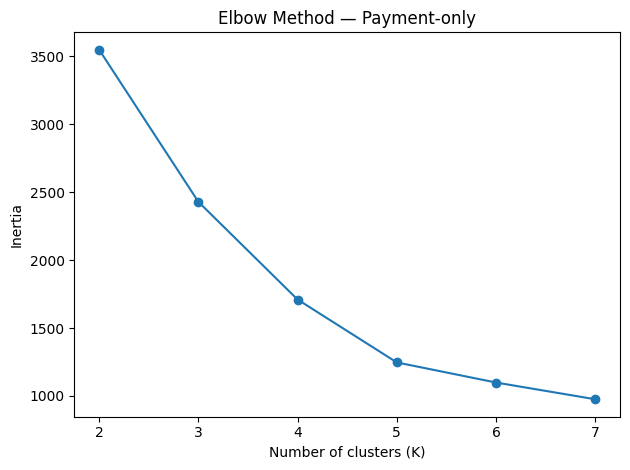

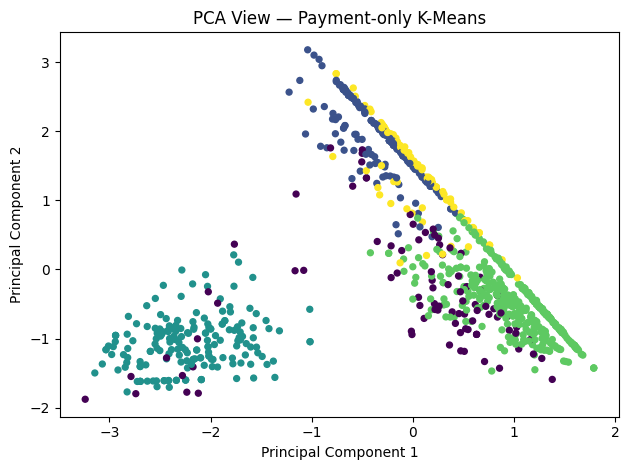

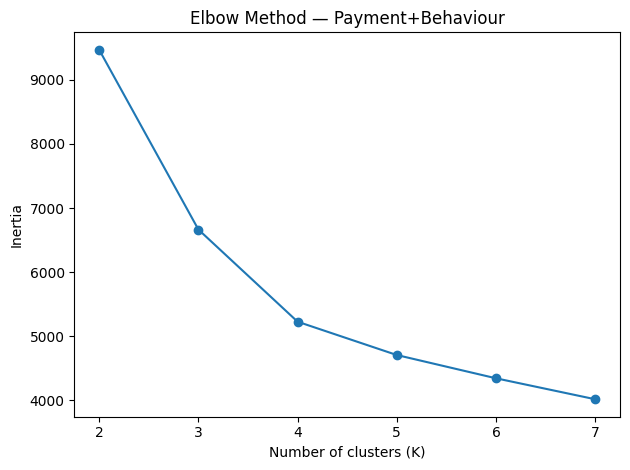

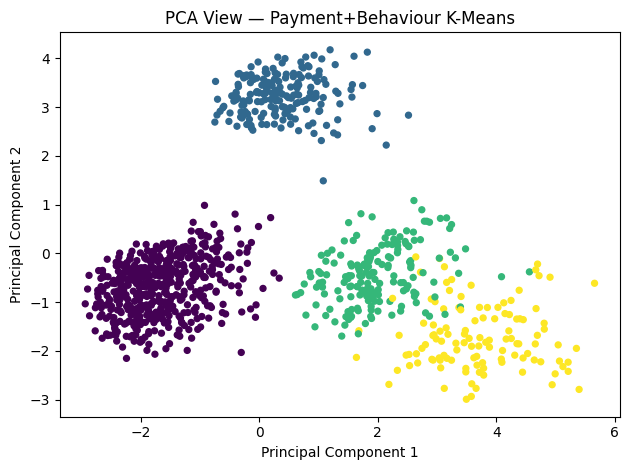


Model comparison:
       feature_set         model  k  silhouette  davies_bouldin     inertia
     Payment-only       K-Means  5    0.536246        0.802332 1246.820055
     Payment-only Agglomerative  5    0.474560        0.794171         NaN
Payment+Behaviour       K-Means  4    0.441626        1.016619 5224.981493
Payment+Behaviour Agglomerative  4    0.419279        1.202911         NaN


In [ ]:
# No train/test split is used: this is an unsupervised clustering task without a target label.
# Internal metrics compare cluster structure on the same data; external validation on new/approved data
# would still be needed before any real business deployment.
# 6. Inspect inertia (Elbow Method) and silhouette across K=2..7, then compare KMeans and Agglomerative.
results = []
best_models = {}
for feature_label, features in [("Payment-only", payment_features),
                                ("Payment+Behaviour", combined_features)]:
    X_scaled, scaler = prepare_matrix(customer, features)
    inertias = []
    silhouettes = []
    k_values = range(2, 8)
    for k in k_values:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(X_scaled)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(X_scaled, labels))
    plt.figure()
    plt.plot(list(k_values), inertias, marker="o")
    plt.title(f"Elbow Method — {feature_label}")
    plt.xlabel("Number of clusters (K)"); plt.ylabel("Inertia")
    plt.tight_layout()
    plt.savefig(PLOT_DIR/(feature_label.lower().replace("+","_").replace("-","_")+"_elbow.png"), dpi=160)
    plt.show(); plt.close()

    # Select the maximum-silhouette candidate among K=2..7 as a reproducible starting point.
    # Inspect the Elbow plot too; business interpretability matters, so do not rely on one metric alone.
    best_k = list(k_values)[int(np.argmax(silhouettes))]
    km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
    km_labels = km.fit_predict(X_scaled)
    results.append({
        "feature_set": feature_label, "model": "K-Means", "k": best_k,
        "silhouette": silhouette_score(X_scaled, km_labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, km_labels),
        "inertia": km.inertia_
    })
    best_models[(feature_label, "K-Means")] = (X_scaled, km_labels, km, features)

    # Hierarchical comparison with same K for a like-for-like comparison.
    ag = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
    ag_labels = ag.fit_predict(X_scaled)
    results.append({
        "feature_set": feature_label, "model": "Agglomerative",
        "k": best_k, "silhouette": silhouette_score(X_scaled, ag_labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, ag_labels),
        "inertia": np.nan
    })
    best_models[(feature_label, "Agglomerative")] = (X_scaled, ag_labels, ag, features)

    # PCA visualization of K-Means solution
    pca = PCA(n_components=2, random_state=42)
    coords = pca.fit_transform(X_scaled)
    plt.figure()
    plt.scatter(coords[:,0], coords[:,1], c=km_labels, s=18)
    plt.title(f"PCA View — {feature_label} K-Means")
    plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2")
    plt.tight_layout()
    plt.savefig(PLOT_DIR/(feature_label.lower().replace("+","_").replace("-","_")+"_pca.png"), dpi=160)
    plt.show(); plt.close()

results_df = pd.DataFrame(results)
results_df.to_csv(ROOT/"model_comparison.csv", index=False)
print("\nModel comparison:\n", results_df.to_string(index=False))


## 8. Save segments and inspect profiles


Cluster profile table:
          transaction_count  total_spend  average_transaction_value  \
cluster                                                              
0                    22.05     18963.20                     869.51   
1                    15.97      7830.01                     491.53   
2                    14.31     39869.75                    2798.37   
3                     9.56     34221.46                    3573.26   

         cashback_usage_rate  average_discount_percent  emi_usage_rate  \
cluster                                                                  
0                       0.70                      5.52            0.08   
1                       0.04                      0.85            0.06   
2                       0.21                      1.99            0.07   
3                       0.31                      2.65            0.79   

         digital_payment_ratio  card_payment_ratio  cash_payment_ratio  \
cluster                            

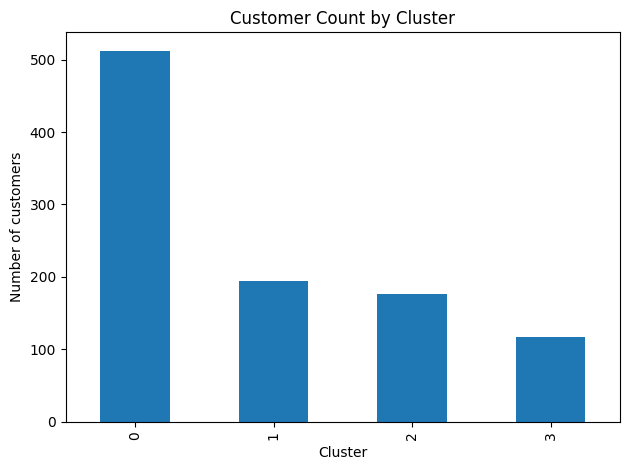

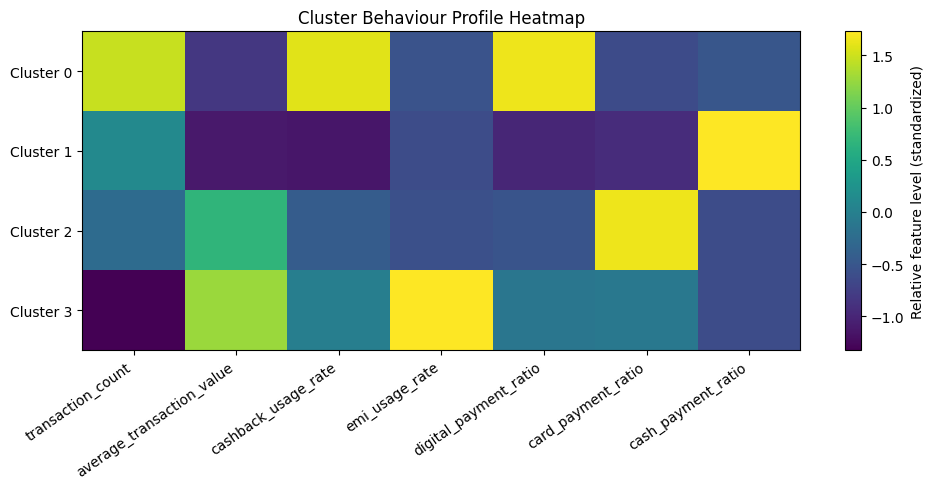


Files generated. Interpret clusters using the profile table; cluster numbers themselves have no inherent meaning.


In [ ]:
# 7. Choose combined-feature KMeans for business profiling, while acknowledging
# final choice depends on metrics and interpretability.
X_scaled, labels, model, features = best_models[("Payment+Behaviour", "K-Means")]
customer["cluster"] = labels
customer.to_csv(ROOT/"customer_segments.csv", index=False)

profile_cols = [
    "transaction_count", "total_spend", "average_transaction_value",
    "cashback_usage_rate", "average_discount_percent", "emi_usage_rate",
    "digital_payment_ratio", "card_payment_ratio", "cash_payment_ratio",
    "emi_payment_ratio", "unknown_payment_ratio", "channel_diversity", "active_months"
]
profile = customer.groupby("cluster")[profile_cols].mean().round(2)
profile["customer_count"] = customer.groupby("cluster").size()
profile.to_csv(ROOT/"cluster_profiles.csv")
print("\nCluster profile table:\n", profile)

plt.figure()
profile["customer_count"].plot(kind="bar")
plt.title("Customer Count by Cluster"); plt.xlabel("Cluster"); plt.ylabel("Number of customers")
plt.tight_layout(); plt.savefig(PLOT_DIR/"cluster_sizes.png", dpi=160); plt.show(); plt.close()

# Normalized heatmap of profile features (for interpretation, not model training).
heat_cols = ["transaction_count","average_transaction_value","cashback_usage_rate",
             "emi_usage_rate","digital_payment_ratio","card_payment_ratio","cash_payment_ratio"]
heat = profile[heat_cols].copy()
heat_norm = (heat - heat.mean()) / heat.std(ddof=0).replace(0, 1)
plt.figure(figsize=(10, 5))
plt.imshow(heat_norm.fillna(0).values, aspect="auto")
plt.xticks(range(len(heat_cols)), heat_cols, rotation=35, ha="right")
plt.yticks(range(len(heat_norm.index)), [f"Cluster {i}" for i in heat_norm.index])
plt.colorbar(label="Relative feature level (standardized)")
plt.title("Cluster Behaviour Profile Heatmap")
plt.tight_layout(); plt.savefig(PLOT_DIR/"cluster_profile_heatmap.png", dpi=160); plt.show(); plt.close()

print("\nFiles generated. Interpret clusters using the profile table; cluster numbers themselves have no inherent meaning.")